# Speech-to-Text: Fine-tuning Whisper Tiny for Multilingual ASR (AR/FR/EN)

Fine-tunes OpenAI Whisper Tiny on Google FLEURS and evaluates with WER/CER.

**Run all cells in order from top to bottom.**

In [1]:
# ============================================================
# CELL 1: Install dependencies
# ============================================================
!pip install -q datasets transformers[torch] accelerate evaluate jiwer librosa soundfile tensorboard

In [2]:
# ============================================================
# CELL 2: Imports and GPU check
# ============================================================
import os
import torch
import numpy as np
from dataclasses import dataclass
from typing import Any, Dict, List, Union

from datasets import load_dataset, Audio, concatenate_datasets
from transformers import (
    WhisperFeatureExtractor,
    WhisperTokenizer,
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
)
import evaluate

print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [3]:
# ============================================================
# CELL 3: Configuration
# ============================================================
MODEL_NAME = "openai/whisper-tiny"
OUTPUT_DIR = "./whisper-multilingual-finetuned"

LANGUAGES = {
    "ar": {"name": "Arabic", "dataset": "google/fleurs", "split_config": "ar_eg"},
    "fr": {"name": "French", "dataset": "google/fleurs", "split_config": "fr_fr"},
    "en": {"name": "English", "dataset": "google/fleurs", "split_config": "en_us"},
}

MAX_SAMPLES_PER_LANG = 2000
MAX_EVAL_SAMPLES_PER_LANG = 300
BATCH_SIZE = 8
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 1e-5
NUM_EPOCHS = 3
WARMUP_STEPS = 200
MAX_INPUT_LENGTH = 30.0

print(f"Model: {MODEL_NAME}")
print(f"Languages: {', '.join([v['name'] for v in LANGUAGES.values()])}")
print(f"Samples per lang: {MAX_SAMPLES_PER_LANG} train / {MAX_EVAL_SAMPLES_PER_LANG} eval")

Model: openai/whisper-tiny
Languages: Arabic, French, English
Samples per lang: 2000 train / 300 eval


In [11]:
feature_extractor = WhisperFeatureExtractor.from_pretrained(MODEL_NAME)
tokenizer = WhisperTokenizer.from_pretrained(MODEL_NAME, language=None, task="transcribe")
processor = WhisperProcessor.from_pretrained(MODEL_NAME, language=None, task="transcribe")

model = WhisperForConditionalGeneration.from_pretrained(MODEL_NAME)
model.config.use_cache = False
model.config.forced_decoder_ids = None
model.generation_config.suppress_tokens = []

print(f"Model loaded: {model.num_parameters() / 1e6:.1f}M parameters")


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Model loaded: 37.8M parameters


In [12]:
# ============================================================
# CELL 5: Load datasets (Google FLEURS)
# ============================================================
def load_language_dataset(lang_code, config, max_train, max_eval):
    print(f"  Loading {config['name']} ({lang_code})...")
    ds = load_dataset(config["dataset"], config["split_config"], split="train")
    ds_test = load_dataset(config["dataset"], config["split_config"], split="test")
    
    if len(ds) > max_train:
        ds = ds.shuffle(seed=42).select(range(max_train))
    if len(ds_test) > max_eval:
        ds_test = ds_test.shuffle(seed=42).select(range(max_eval))
    
    ds = ds.rename_column("transcription", "sentence")
    ds_test = ds_test.rename_column("transcription", "sentence")
    ds = ds.map(lambda x: {"language": lang_code}, batched=False)
    ds_test = ds_test.map(lambda x: {"language": lang_code}, batched=False)
    
    print(f"    Train: {len(ds)} | Test: {len(ds_test)}")
    return ds, ds_test


print("Loading datasets...")
train_datasets = []
eval_datasets = []

for lang_code, config in LANGUAGES.items():
    train_ds, eval_ds = load_language_dataset(
        lang_code, config, MAX_SAMPLES_PER_LANG, MAX_EVAL_SAMPLES_PER_LANG
    )
    train_datasets.append(train_ds)
    eval_datasets.append(eval_ds)

raw_train = concatenate_datasets(train_datasets).shuffle(seed=42)
raw_eval = concatenate_datasets(eval_datasets).shuffle(seed=42)

print(f"\nCombined -- Train: {len(raw_train)} | Eval: {len(raw_eval)}")

Loading datasets...
  Loading Arabic (ar)...
    Train: 2000 | Test: 300
  Loading French (fr)...
    Train: 2000 | Test: 300
  Loading English (en)...
    Train: 2000 | Test: 300

Combined -- Train: 6000 | Eval: 900


In [13]:
# ============================================================
# CELL 6: Preprocess audio
# ============================================================
raw_train = raw_train.cast_column("audio", Audio(sampling_rate=16000))
raw_eval = raw_eval.cast_column("audio", Audio(sampling_rate=16000))


def prepare_dataset(batch):
    try:
        audio = batch["audio"]
        batch["input_features"] = feature_extractor(
            audio["array"], sampling_rate=audio["sampling_rate"]
        ).input_features[0]
        batch["labels"] = tokenizer(batch["sentence"]).input_ids
        batch["input_length"] = len(audio["array"]) / audio["sampling_rate"]
    except Exception:
        batch["input_features"] = None
        batch["labels"] = None
        batch["input_length"] = 999.0
    return batch


print("Preprocessing training set...")
train_dataset = raw_train.map(prepare_dataset, remove_columns=raw_train.column_names, num_proc=1)

print("Preprocessing evaluation set...")
eval_dataset = raw_eval.map(prepare_dataset, remove_columns=raw_eval.column_names, num_proc=1)

# Filter corrupted + long audio
train_dataset = train_dataset.filter(lambda x: x["input_length"] <= MAX_INPUT_LENGTH and x["input_length"] < 999.0)
eval_dataset = eval_dataset.filter(lambda x: x["input_length"] <= MAX_INPUT_LENGTH and x["input_length"] < 999.0)

print(f"After filtering -- Train: {len(train_dataset)} | Eval: {len(eval_dataset)}")

Preprocessing training set...
Preprocessing evaluation set...
After filtering -- Train: 5991 | Eval: 899


In [14]:
# ============================================================
# CELL 7: Data collator
# ============================================================
@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any

    def __call__(self, features: List[Dict[str, Union[List[int], torch.Tensor]]]) -> Dict[str, torch.Tensor]:
        input_features = [{"input_features": f["input_features"]} for f in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")

        label_features = [{"input_ids": f["labels"]} for f in features]
        labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")

        labels = labels_batch["input_ids"].masked_fill(
            labels_batch.attention_mask.ne(1), -100
        )

        if (labels[:, 0] == self.processor.tokenizer.bos_token_id).all().cpu().item():
            labels = labels[:, 1:]

        batch["labels"] = labels
        return batch


data_collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor)
print("Data collator ready.")

Data collator ready.


In [15]:
# ============================================================
# CELL 8: Evaluation metrics (WER + CER)
# ============================================================
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")


def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids
    label_ids[label_ids == -100] = tokenizer.pad_token_id
    pred_str = tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = tokenizer.batch_decode(label_ids, skip_special_tokens=True)
    wer = wer_metric.compute(predictions=pred_str, references=label_str)
    cer = cer_metric.compute(predictions=pred_str, references=label_str)
    return {"wer": round(wer * 100, 2), "cer": round(cer * 100, 2)}


print("Metrics ready: WER, CER")

Metrics ready: WER, CER


In [16]:
# ============================================================
# CELL 9: Training configuration
# ============================================================
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    learning_rate=LEARNING_RATE,
    num_train_epochs=NUM_EPOCHS,
    warmup_steps=WARMUP_STEPS,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
    predict_with_generate=True,
    generation_max_length=225,
    report_to="tensorboard",
    push_to_hub=False,
    dataloader_num_workers=2,
    remove_unused_columns=False,
)

print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION}")
print(f"FP16: {training_args.fp16}")

Effective batch size: 32
FP16: True


In [17]:
# ============================================================
# CELL 10: Train
# ============================================================
trainer = Seq2SeqTrainer(
    args=training_args,
    model=model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=processor.feature_extractor,
)

torch.cuda.empty_cache()
print("Starting training...")
train_result = trainer.train()

trainer.save_model(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)

print(f"\nDone. Model saved to {OUTPUT_DIR}")
print(f"Train loss: {train_result.training_loss:.4f}")

Starting training...


Epoch,Training Loss,Validation Loss,Wer,Cer
1,3.271759,0.806966,41.050000,16.630000
2,2.441336,0.740025,40.630000,16.170000
3,2.017616,0.731755,39.440000,15.810000


Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.log

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['proj_out.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Done. Model saved to ./whisper-multilingual-finetuned
Train loss: 3.2402


In [18]:
# ============================================================
# CELL 11: Overall evaluation
# ============================================================
print("Evaluating...")
eval_results = trainer.evaluate()

print(f"\n{'='*50}")
print(f"  OVERALL RESULTS")
print(f"{'='*50}")
print(f"  WER: {eval_results['eval_wer']:.2f}%")
print(f"  CER: {eval_results['eval_cer']:.2f}%")
print(f"  Loss: {eval_results['eval_loss']:.4f}")
print(f"{'='*50}")

Evaluating...



  OVERALL RESULTS
  WER: 39.44%
  CER: 15.81%
  Loss: 0.7318


In [19]:
# ============================================================
# CELL 12: Per-language evaluation
# ============================================================
print("Per-language evaluation:")
print(f"{'Language':<12} {'WER (%)':<10} {'CER (%)':<10} {'Samples':<10}")
print("-" * 42)

per_lang_results = {}

for lang_code, config in LANGUAGES.items():
    lang_test = load_dataset(config["dataset"], config["split_config"], split="test")
    if len(lang_test) > MAX_EVAL_SAMPLES_PER_LANG:
        lang_test = lang_test.shuffle(seed=42).select(range(MAX_EVAL_SAMPLES_PER_LANG))
    
    lang_test = lang_test.rename_column("transcription", "sentence")
    lang_test = lang_test.cast_column("audio", Audio(sampling_rate=16000))
    
    predictions = []
    references = []
    
    for sample in lang_test:
        audio = sample["audio"]
        input_features = processor(
            audio["array"], sampling_rate=audio["sampling_rate"], return_tensors="pt"
        ).input_features
        if torch.cuda.is_available():
            input_features = input_features.cuda()
        with torch.no_grad():
            predicted_ids = model.generate(input_features, max_length=225)
        transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
        predictions.append(transcription)
        references.append(sample["sentence"])
    
    lang_wer = wer_metric.compute(predictions=predictions, references=references) * 100
    lang_cer = cer_metric.compute(predictions=predictions, references=references) * 100
    per_lang_results[lang_code] = {"wer": lang_wer, "cer": lang_cer, "samples": len(lang_test)}
    print(f"{config['name']:<12} {lang_wer:<10.2f} {lang_cer:<10.2f} {len(lang_test):<10}")

print("-" * 42)

Per-language evaluation:
Language     WER (%)    CER (%)    Samples   
------------------------------------------
Arabic       53.97      19.54      300       
French       43.87      19.31      300       
English      21.92      8.27       300       
------------------------------------------


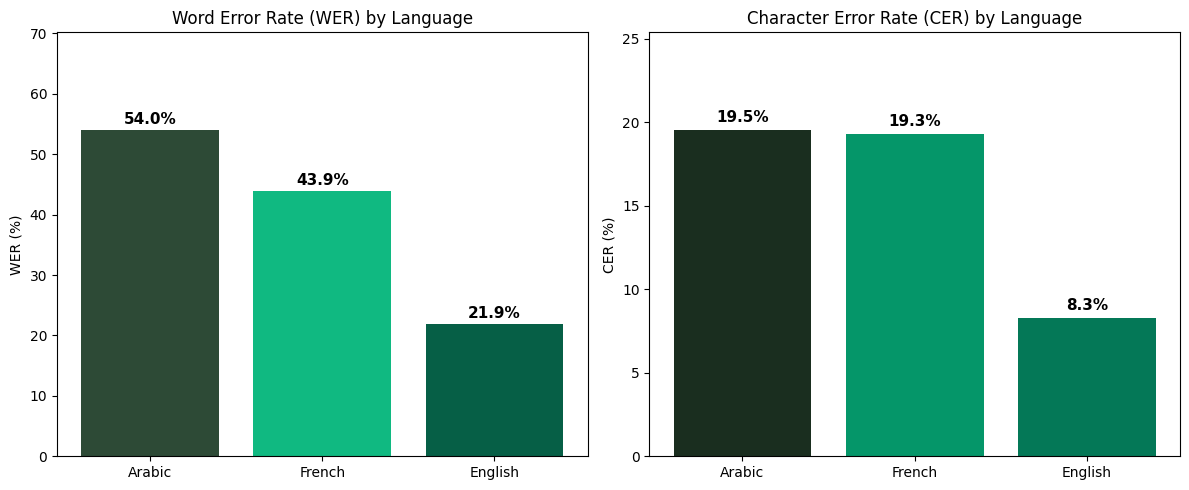

Chart saved.


In [20]:
# ============================================================
# CELL 13: Visualize results
# ============================================================
import matplotlib.pyplot as plt

langs = [LANGUAGES[k]["name"] for k in per_lang_results]
wers = [per_lang_results[k]["wer"] for k in per_lang_results]
cers = [per_lang_results[k]["cer"] for k in per_lang_results]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

bars1 = ax[0].bar(langs, wers, color=["#2d4a36", "#10b981", "#065f46"])
ax[0].set_title("Word Error Rate (WER) by Language")
ax[0].set_ylabel("WER (%)")
ax[0].set_ylim(0, max(wers) * 1.3)
for bar, val in zip(bars1, wers):
    ax[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{val:.1f}%",
              ha="center", fontsize=11, fontweight="bold")

bars2 = ax[1].bar(langs, cers, color=["#1a2e1f", "#059669", "#047857"])
ax[1].set_title("Character Error Rate (CER) by Language")
ax[1].set_ylabel("CER (%)")
ax[1].set_ylim(0, max(cers) * 1.3)
for bar, val in zip(bars2, cers):
    ax[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{val:.1f}%",
              ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("stt_evaluation_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved.")

In [23]:
# ============================================================
# CELL 14: Test inference
# ============================================================
import torch

print("Inference test:\n")

model.eval()
if torch.cuda.is_available():
    model = model.cuda()

for lang_code, config in LANGUAGES.items():
    sample_ds = load_dataset(config["dataset"], config["split_config"], split="test")
    sample_ds = sample_ds.rename_column("transcription", "sentence")
    sample_ds = sample_ds.cast_column("audio", Audio(sampling_rate=16000))
    sample = sample_ds[0]
    
    audio = sample["audio"]
    input_features = processor(
        audio["array"], sampling_rate=audio["sampling_rate"], return_tensors="pt"
    ).input_features
    
    if torch.cuda.is_available():
        input_features = input_features.cuda()
    
    with torch.no_grad():
        predicted_ids = model.generate(input_features, max_length=225)
    
    transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
    
    print(f"[{config['name']}]")
    print(f"  Reference: {sample['sentence']}")
    print(f"  Predicted: {transcription}")
    print()


Inference test:

[Arabic]
  Reference: تشكلت في المحيط الأطلسي اليوم عاشر عاصفة مُسماة لموسم الأعاصير الأطلسية العاصفة شبه الاستوائية جيري
  Predicted: دشكلت في المحيد الأطلسل يوم عشر عاصفة مسماء لموسم الأعاصير الأطلسية العاصفة شبه الاستوائية الجاري

[French]
  Reference: l'accident a eu lieu en terrain montagneux et il semblerait que cela ait été causé par un incendie malveillant
  Predicted: l'accident a eu lieu en terrain montagneux et il semblerait que cela était causée par un incendimalveillance

[English]
  Reference: however due to the slow communication channels styles in the west could lag behind by 25 to 30 year
  Predicted:  However due to the slow communication channels styles in the west could lag behind by 25 to 30 years



In [24]:
# ============================================================
# CELL 15: Save summary
# ============================================================
import json

summary = {
    "model_base": MODEL_NAME,
    "dataset": "google/fleurs",
    "languages": list(LANGUAGES.keys()),
    "training": {
        "epochs": NUM_EPOCHS,
        "batch_size": BATCH_SIZE * GRADIENT_ACCUMULATION,
        "learning_rate": LEARNING_RATE,
        "train_samples": len(train_dataset),
        "eval_samples": len(eval_dataset),
    },
    "results": {
        "overall": {
            "wer": eval_results.get("eval_wer", None),
            "cer": eval_results.get("eval_cer", None),
        },
        "per_language": per_lang_results,
    },
}

with open(os.path.join(OUTPUT_DIR, "training_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Summary saved.")
print(f"\nTo use: pipeline('automatic-speech-recognition', model='{OUTPUT_DIR}')")

Summary saved.

To use: pipeline('automatic-speech-recognition', model='./whisper-multilingual-finetuned')
